# 聚类算法对比示例

本 Notebook 演示了以下聚类算法的使用：

- 原型聚类：KMeans、学习向量量化（LVQ）、高斯混合模型（GMM）
- 密度聚类：DBSCAN
- 层次聚类：Agglomerative Clustering

其中，LVQ 部分使用了 `sklearn_lvq` 库，请确保已安装：

```bash
!pip install sklearn_lvq
```

下面开始代码示例。

In [17]:
!pip install sklearn_lvq

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

# 对于 LVQ，这里使用 sklearn_lvq 库的 GlvqModel
try:
    from sklearn_lvq import GlvqModel
except ImportError:
    print('请安装 sklearn_lvq：pip install sklearn_lvq')

# 生成合成数据
n_cluster = 3
X, y_true = make_blobs(n_samples=100, centers=n_cluster, cluster_std=1, random_state=0)

# 为了便于展示，将数据点转换为二维
print('数据维度:', X.shape)

数据维度: (100, 2)


In [2]:
# KMeans 聚类
kmeans = KMeans(n_clusters=n_cluster, random_state=0)
labels_kmeans = kmeans.fit_predict(X)

print('KMeans 完成')

KMeans 完成


In [3]:
# 高斯混合模型聚类 (GMM)
gmm = GaussianMixture(n_components=n_cluster, random_state=0)
gmm.fit(X)
labels_gmm = gmm.predict(X)

print('Gaussian Mixture 完成')

Gaussian Mixture 完成


In [4]:
# DBSCAN 密度聚类
dbscan = DBSCAN(eps=0.8, min_samples=10)
labels_dbscan = dbscan.fit_predict(X)

print('DBSCAN 完成')

DBSCAN 完成


In [5]:
# 层次聚类 (Agglomerative Clustering)
agglo = AgglomerativeClustering(n_clusters=n_cluster)
labels_agglo = agglo.fit_predict(X)

print('Agglomerative Clustering 完成')

Agglomerative Clustering 完成


In [6]:
# 学习向量量化 (LVQ) 
# 注意：LVQ 是一种监督学习方法，因此这里使用数据的真实标签来训练模型
if 'GlvqModel' in globals():
    lvq = GlvqModel()
    lvq.fit(X, y_true)  
    labels_lvq = lvq.predict(X)
    print('LVQ 完成')
else:
    labels_lvq = None
    print('未安装 sklearn_lvq，LVQ 无法运行')

AttributeError: module 'numpy' has no attribute 'math'

C:\Users\CZL\AppData\Local\Temp\ipykernel_14204\2384096380.py:36: UserWarning: Glyph 26410 (\N{CJK UNIFIED IDEOGRAPH-672A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\CZL\AppData\Local\Temp\ipykernel_14204\2384096380.py:36: UserWarning: Glyph 36816 (\N{CJK UNIFIED IDEOGRAPH-8FD0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\CZL\AppData\Local\Temp\ipykernel_14204\2384096380.py:36: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\CZL\miniconda3\envs\py3.12\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26410 (\N{CJK UNIFIED IDEOGRAPH-672A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\CZL\miniconda3\envs\py3.12\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 36816 (\N{CJK UNIFIED IDEOGRAPH-8FD0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\CZL\miniconda3

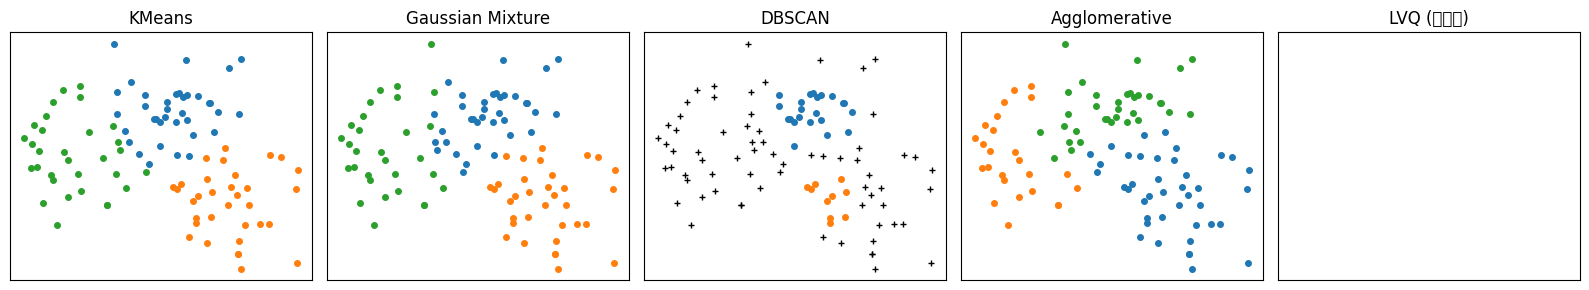

In [9]:
# 绘制所有聚类结果对比图
plt.figure(figsize=(16, 3))

algorithms = [
    (labels_kmeans, 'KMeans'),
    (labels_gmm, 'Gaussian Mixture'),
    (labels_dbscan, 'DBSCAN'),
    (labels_agglo, 'Agglomerative'),
    (labels_lvq, 'LVQ (GlvqModel)' if labels_lvq is not None else 'LVQ (未运行)')
]

for i, (labels, title) in enumerate(algorithms):
    plt.subplot(1, len(algorithms), i+1)
    # 对于 DBSCAN，噪声点的标签为 -1
    unique_labels = np.unique(labels) if labels is not None else []
    
    if labels is not None and -1 in unique_labels:
        colors = [plt.cm.Spectral(each)
                  for each in np.linspace(0, 1, len(unique_labels))]
    
    if labels is not None:
        for k in unique_labels:
            class_member_mask = (labels == k)
            xy = X[class_member_mask]
            
            if k == -1:
                # 噪声点
                plt.plot(xy[:, 0], xy[:, 1], 'k+', markersize=4, label='噪声')
            else:
                plt.plot(xy[:, 0], xy[:, 1], 'o', markersize=4, label='簇 %d' % k)
    
    plt.title(title)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()